# NumPy y pandas · NumPy y pandas aplicados

Problemas de análisis con datos generados con semilla. Primero, una matriz de lecturas diarias de viento de ocho estaciones canarias que se resume por ejes y por meses, se compara con pandas y se guarda en varios formatos (`.npy`, `.npz`, texto y MATLAB); después, un sensor con lecturas inválidas tratado con arrays con máscara; y por último tres tablas de pandas (localidades, usuarios y repartos de cine) para practicar `loc`, `iloc`, `query`, los métodos `.str`, los extremos por grupo y las tablas de contingencia. Ideas del [Curso de Python científico](https://github.com/hmedrano/curso-python-cientifico), del taller [AtmosCol 2023 de Project Pythia](https://github.com/ProjectPythia/AtmosCol-2023) y de un [cuaderno de ejercicios de pandas en Kaggle](https://www.kaggle.com/code/gastonocana/ejercicios-pandas). Todos los valores numéricos son inventados.

## 1. Resumen de una matriz de viento por ejes

Generar con `np.random.default_rng(2026)` la velocidad media diaria del viento (km/h) en 8 estaciones canarias desde el 1 de enero de 2023 hasta el 31 de diciembre de 2025: una matriz días × estaciones con una media propia de cada estación, una componente estacional que hace que el alisio sople más fuerte en verano y ruido normal, sin valores negativos. Calcular el mínimo, el máximo, la media y la desviación típica de cada estación (`axis=0`) y la media de todas las estaciones en cada día (`axis=1`), y el día más ventoso en promedio.

In [1]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(2026)
estaciones = ["Gando", "Tenerife Sur", "Los Rodeos", "Lanzarote", "Fuerteventura", "La Palma", "El Hierro", "La Gomera"]
fechas = pd.date_range("2023-01-01", "2025-12-31", freq="D")
media = np.array([28, 24, 18, 22, 26, 16, 20, 14])
amplitud = np.array([10, 8, 5, 7, 9, 5, 6, 4])
# Máximo estacional hacia el día 200 del año (mediados de julio)
estacional = np.cos(2 * np.pi * (fechas.day_of_year.to_numpy() - 200) / 365.25)
viento = media + amplitud * estacional[:, None] + rng.normal(0, 5, (len(fechas), len(estaciones)))
viento = np.clip(viento, 0, None).round(1)
print("Forma (días, estaciones):", viento.shape)

print(f"\n{'Estación':<14}{'Mín':>6}{'Máx':>6}{'Media':>7}{'Desv.':>7}")
for nombre, mn, mx, me, de in zip(estaciones, viento.min(axis=0), viento.max(axis=0),
                                  viento.mean(axis=0), viento.std(axis=0)):
    print(f"{nombre:<14}{mn:6.1f}{mx:6.1f}{me:7.2f}{de:7.2f}")

por_dia = viento.mean(axis=1)
print("\nMedia de todas las estaciones los tres primeros días:", por_dia[:3].round(2))
dia = por_dia.argmax()
print(f"Día más ventoso en promedio: {fechas[dia]:%d/%m/%Y} ({por_dia[dia]:.2f} km/h)")
assert por_dia.shape == (len(fechas),) and viento.min() >= 0
assert np.allclose(viento.max(axis=0), [max(columna) for columna in viento.T])
assert np.isclose(por_dia[dia], max(sum(fila) / len(fila) for fila in viento))

Forma (días, estaciones): (1096, 8)

Estación         Mín   Máx  Media  Desv.
Gando            6.6  53.9  27.97   8.69
Tenerife Sur     5.2  43.6  24.17   7.36
Los Rodeos       0.0  36.0  18.07   6.02
Lanzarote        1.2  44.0  21.93   7.26
Fuerteventura    0.0  45.9  25.95   8.08
La Palma         0.0  35.1  16.00   6.20
El Hierro        2.4  39.2  19.98   6.28
La Gomera        0.0  33.2  13.98   5.73

Media de todas las estaciones los tres primeros días: [14.06 14.56 13.48]
Día más ventoso en promedio: 07/08/2023 (31.34 km/h)


## 2. La lectura máxima y la estación más ventosa de cada día

Localizar la lectura más alta de toda la matriz con `argmax`, que devuelve la posición en el array aplanado, y convertirla en (fila, columna) con `np.unravel_index` para saber en qué fecha y estación se produjo. Obtener también la fecha del máximo de cada estación y contar cuántos días ha sido cada estación la más ventosa, combinando `argmax(axis=1)` con `np.bincount`.

In [2]:
posicion = viento.argmax()
fila, columna = np.unravel_index(posicion, viento.shape)
print(f"Posición plana {posicion} → fila {fila}, columna {columna}")
print(f"Máximo absoluto: {viento[fila, columna]} km/h en {estaciones[columna]} el {fechas[fila]:%d/%m/%Y}")

print()
for nombre, d in zip(estaciones, viento.argmax(axis=0)):
    print(f"{nombre:<14} máximo el {fechas[d]:%d/%m/%Y}")

veces = np.bincount(viento.argmax(axis=1), minlength=len(estaciones))
print("\nDías como estación más ventosa:", dict(zip(estaciones, veces.tolist())))

fuerza_bruta = max((viento[i, j], i, j) for i in range(viento.shape[0]) for j in range(viento.shape[1]))
assert (fila, columna) == fuerza_bruta[1:] and viento[fila, columna] == viento.max()
assert veces.sum() == len(fechas)

Posición plana 4440 → fila 555, columna 0
Máximo absoluto: 53.9 km/h en Gando el 09/07/2024

Gando          máximo el 09/07/2024
Tenerife Sur   máximo el 29/07/2024
Los Rodeos     máximo el 18/07/2025
Lanzarote      máximo el 08/06/2023
Fuerteventura  máximo el 10/08/2025
La Palma       máximo el 27/07/2023
El Hierro      máximo el 01/09/2024
La Gomera      máximo el 04/05/2024

Días como estación más ventosa: {'Gando': 474, 'Tenerife Sur': 170, 'Los Rodeos': 26, 'Lanzarote': 84, 'Fuerteventura': 271, 'La Palma': 16, 'El Hierro': 46, 'La Gomera': 9}


## 3. Medias mensuales sin bucles sobre los días

Calcular la media de cada mes del año (enero de los tres años juntos, febrero…) en cada estación de tres formas: con una máscara booleana por mes, con `np.bincount(meses, weights=...)`, que suma los pesos de cada etiqueta, dividido entre el número de días de cada mes, y con `groupby` de pandas. Comprobar que coinciden y dibujar el ciclo anual de cada estación.

Días de cada mes en los tres años: [93, 85, 93, 90, 93, 90, 93, 93, 90, 93, 90, 93]
                ene   feb   mar   abr   may   jun   jul   ago   sep   oct   nov   dic
Gando          18.7  19.1  22.6  27.3  32.7  36.1  38.2  36.3  33.2  29.0  22.5  19.3
Tenerife Sur   16.7  18.2  19.8  24.3  27.8  30.6  31.5  30.1  28.8  24.6  20.4  17.0
Los Rodeos     12.9  14.2  15.1  17.7  20.4  22.4  22.7  22.7  20.5  19.0  15.8  13.3
Lanzarote      14.5  14.7  17.3  22.2  24.3  28.1  29.4  28.6  25.1  22.5  18.8  17.1
Fuerteventura  16.7  18.7  21.2  25.8  29.9  32.9  35.3  33.2  30.7  26.1  22.4  18.1
La Palma       11.1  12.1  13.5  15.1  18.0  20.4  21.1  20.2  18.7  16.3  13.5  11.8
El Hierro      14.3  15.0  16.8  20.3  21.9  25.0  25.8  25.0  22.7  19.7  17.5  15.6
La Gomera       9.9  11.2  12.1  14.4  15.6  16.8  17.7  17.2  16.5  13.7  11.9  10.6


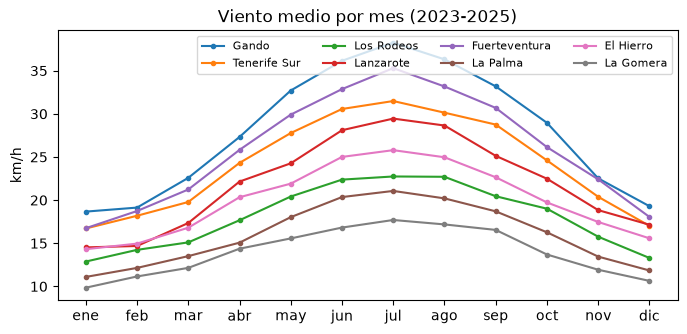

In [3]:
import matplotlib.pyplot as plt

MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
meses = fechas.month.to_numpy()

con_mascaras = np.array([viento[meses == m].mean(axis=0) for m in range(1, 13)])

dias_mes = np.bincount(meses)[1:]
con_bincount = np.column_stack([np.bincount(meses, weights=viento[:, j])[1:] / dias_mes
                                for j in range(len(estaciones))])

df_viento = pd.DataFrame(viento, index=fechas, columns=estaciones)
con_pandas = df_viento.groupby(df_viento.index.month).mean()

print("Días de cada mes en los tres años:", dias_mes.tolist())
with pd.option_context("display.width", 120):
    print(pd.DataFrame(con_bincount, index=MESES, columns=estaciones).round(1).T)
assert con_bincount.shape == (12, 8)
assert np.allclose(con_mascaras, con_bincount) and np.allclose(con_bincount, con_pandas.to_numpy())

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(MESES, con_bincount, marker="o", markersize=3)
ax.set(ylabel="km/h", title="Viento medio por mes (2023-2025)")
ax.legend(estaciones, ncols=4, fontsize=8)
plt.show()

## 4. Medias de cada mes de cada año con `np.add.reduceat`

Como los días están ordenados, cada mes concreto (enero de 2023, febrero de 2023…) es un bloque de filas consecutivas. Encontrar dónde empieza cada bloque, sumar los bloques con `np.add.reduceat(viento, inicios, axis=0)` y dividir entre su número de días para obtener las 36 medias mensuales de cada estación. Comparar con `resample("ME")` de pandas y mostrar la tabla año × mes de Gando con `reshape`.

In [4]:
año_mes = fechas.year.to_numpy() * 100 + meses
inicios = np.flatnonzero(np.r_[True, año_mes[1:] != año_mes[:-1]])
longitudes = np.diff(np.r_[inicios, len(viento)])
mensual = np.add.reduceat(viento, inicios, axis=0) / longitudes[:, None]
print("Bloques:", len(inicios), "| primeros inicios:", inicios[:4].tolist(), "| forma:", mensual.shape)

gando = pd.DataFrame(mensual[:, 0].reshape(3, 12), index=[2023, 2024, 2025], columns=MESES)
print("\nGando, media mensual (km/h):")
print(gando.round(1))

con_resample = df_viento.resample("ME").mean()
assert mensual.shape == (36, 8) and longitudes.sum() == len(fechas)
assert np.allclose(mensual, con_resample.to_numpy())

Bloques: 36 | primeros inicios: [0, 31, 59, 90] | forma: (36, 8)

Gando, media mensual (km/h):
       ene   feb   mar   abr   may   jun   jul   ago   sep   oct   nov   dic
2023  20.3  19.3  23.5  26.7  33.1  35.5  38.1  35.6  33.4  29.1  23.0  19.4
2024  17.9  19.7  22.4  28.0  32.4  36.9  37.9  36.0  33.0  29.1  22.6  19.7
2025  17.8  18.4  21.9  27.2  32.6  36.0  38.7  37.3  33.1  28.7  21.9  18.8


## 5. Anomalías respecto a la climatología

La anomalía de un día es lo que se aparta de la media de su mes. Restar a cada fila la media mensual que le corresponde usando `con_bincount[meses - 1]` como índice (una fila por día) y comprobar que las anomalías de cada mes tienen media cero. Encontrar el día de mayor anomalía positiva de cada estación y contar los días en que todas las estaciones soplaron por encima de lo normal a la vez.

In [5]:
climatologia = con_bincount[meses - 1]
anomalias = viento - climatologia
print("Forma de la climatología por día:", climatologia.shape)

for nombre, d, a in zip(estaciones, anomalias.argmax(axis=0), anomalias.max(axis=0)):
    print(f"{nombre:<14} {fechas[d]:%d/%m/%Y}  +{a:.1f} km/h")

todas = (anomalias > 0).all(axis=1)
print(f"\nDías con todas las estaciones por encima de lo normal: {todas.sum()}")
print("Los tres primeros:", [f"{f:%d/%m/%Y}" for f in fechas[todas][:3]])

medias_anomalias = np.array([anomalias[meses == m].mean(axis=0) for m in range(1, 13)])
assert np.allclose(medias_anomalias, 0)
assert todas.sum() == sum(all(a > 0 for a in fila) for fila in anomalias)

Forma de la climatología por día: (1096, 8)
Gando          26/05/2024  +16.0 km/h
Tenerife Sur   07/01/2023  +15.2 km/h
Los Rodeos     10/11/2025  +18.3 km/h
Lanzarote      08/06/2023  +15.9 km/h
Fuerteventura  23/01/2025  +17.4 km/h
La Palma       23/02/2023  +14.7 km/h
El Hierro      01/09/2024  +16.5 km/h
La Gomera      04/05/2024  +17.6 km/h

Días con todas las estaciones por encima de lo normal: 6
Los tres primeros: ['13/10/2024', '06/12/2024', '26/08/2025']


## 6. Guardar y cargar en binario: `.npy` y `.npz`

Guardar la matriz de viento con `np.save` y recuperarla con `np.load`. Guardar después en un único fichero la matriz, las fechas y los nombres de las estaciones con `np.savez`, que asocia un nombre a cada array, y con `np.savez_compressed`. Comprobar que todo se recupera igual (tipo incluido) y comparar el tamaño de los ficheros.

In [6]:
from pathlib import Path

np.save("viento.npy", viento)
recuperado = np.load("viento.npy")
print("npy:", recuperado.shape, recuperado.dtype)
assert np.array_equal(recuperado, viento) and recuperado.dtype == viento.dtype

arrays = {"viento": viento, "fechas": fechas.to_numpy().astype("datetime64[D]"), "estaciones": np.array(estaciones)}
np.savez("viento.npz", **arrays)
np.savez_compressed("viento_comprimido.npz", **arrays)

with np.load("viento.npz") as datos:
    print("npz contiene:", datos.files)
    print("Primeras fechas:", datos["fechas"][:2], "| estaciones:", datos["estaciones"].dtype)
    assert all(np.array_equal(datos[clave], valor) for clave, valor in arrays.items())

for fichero in ["viento.npy", "viento.npz", "viento_comprimido.npz"]:
    print(f"{fichero:<22}{Path(fichero).stat().st_size / 1024:8.1f} KB")
assert Path("viento_comprimido.npz").stat().st_size < Path("viento.npz").stat().st_size

npy: (1096, 8) float64


npz contiene: ['viento', 'fechas', 'estaciones']
Primeras fechas: ['2023-01-01' '2023-01-02'] | estaciones: <U13
viento.npy                68.6 KB
viento.npz                78.2 KB
viento_comprimido.npz     18.8 KB


## 7. Guardar y cargar en texto: `savetxt` y `loadtxt`

Guardar en `medias_mensuales.csv` la tabla de medias mensuales (una columna con el número de mes y una por estación) con `np.savetxt`, usando comas como separador, una cabecera con los nombres sin el `#` que añade por defecto y un formato distinto por columna (`%d` para el mes y dos decimales para el resto). Leerla con `np.loadtxt` saltando la cabecera, leer solo el mes y Gando con `usecols` y `unpack`, y comprobar que pandas lee el mismo fichero con sus nombres de columna.

In [7]:
tabla = np.column_stack([np.arange(1, 13), con_bincount])
np.savetxt("medias_mensuales.csv", tabla, fmt=["%d"] + ["%.2f"] * len(estaciones), delimiter=",",
           header="mes," + ",".join(estaciones), comments="", encoding="utf-8")
print(*Path("medias_mensuales.csv").read_text(encoding="utf-8").splitlines()[:3], sep="\n")

leida = np.loadtxt("medias_mensuales.csv", delimiter=",", skiprows=1, encoding="utf-8")
mes, gando_mes = np.loadtxt("medias_mensuales.csv", delimiter=",", skiprows=1, usecols=(0, 1), unpack=True,
                            encoding="utf-8")
print("\nloadtxt:", leida.shape, "| Gando en julio:", gando_mes[6])

con_read_csv = pd.read_csv("medias_mensuales.csv")
print("read_csv:", con_read_csv.columns[:3].tolist())
assert leida.shape == (12, 9) and np.allclose(leida[:, 1:], con_bincount, atol=0.005)
assert np.array_equal(mes, np.arange(1, 13)) and np.allclose(con_read_csv.to_numpy(), leida)

mes,Gando,Tenerife Sur,Los Rodeos,Lanzarote,Fuerteventura,La Palma,El Hierro,La Gomera
1,18.67,16.71,12.88,14.52,16.75,11.10,14.31,9.85
2,19.13,18.19,14.24,14.68,18.74,12.14,14.96,11.15

loadtxt: (12, 9) | Gando en julio: 38.25
read_csv: ['mes', 'Gando', 'Tenerife Sur']


## 8. Intercambiar datos con MATLAB: `savemat` y `loadmat`

`scipy.io` lee y escribe ficheros `.mat`. Comprobar que SciPy está instalado porque es una dependencia de scikit-learn y guardar en `viento.mat` la matriz, los nombres de las estaciones y el número de día. Al leerlo con `loadmat`, ver qué claves añade, que los vectores vuelven como matrices de una fila (en MATLAB todo tiene al menos dos dimensiones) y que los textos vuelven rellenos con espacios hasta la misma longitud.

In [8]:
from importlib.metadata import requires, version

from scipy.io import loadmat, savemat

print("scikit-learn necesita:", [r for r in requires("scikit-learn") if r.startswith("scipy")])
print("SciPy instalado:", version("scipy"))

savemat("viento.mat", {"viento": viento, "estaciones": estaciones, "dia": np.arange(len(fechas))})
mat = loadmat("viento.mat")
print("Claves:", list(mat))
print("viento:", mat["viento"].shape, "| dia:", mat["dia"].shape)
print("estaciones:", mat["estaciones"][:3])

nombres = [s.rstrip() for s in mat["estaciones"]]
assert np.array_equal(mat["viento"], viento) and nombres == estaciones
assert np.array_equal(mat["dia"].ravel(), np.arange(len(fechas)))

scikit-learn necesita: ['scipy>=1.10.0']
SciPy instalado: 1.18.1
Claves: ['__header__', '__version__', '__globals__', 'viento', 'estaciones', 'dia']
viento: (1096, 8) | dia: (1, 1096)
estaciones: ['Gando        ' 'Tenerife Sur ' 'Los Rodeos   ']


## 9. Lecturas inválidas con arrays con máscara

Un sensor de temperatura escribe −999 cuando falla. Simular 30 lecturas con 5 fallos y ver que la media directa no tiene sentido. Marcarlas como inválidas con `np.ma.masked_equal` y obtener la media, la máscara, el número de lecturas válidas (`count`), el array rellenando los huecos con la media (`filled`) y solo los valores válidos (`compressed`). Hacer lo mismo cambiando −999 por `np.nan` y comparar `mean` con `nanmean`. Por último, con tres sensores, enmascarar también las lecturas fuera del rango físico con `masked_outside` y calcular la media de cada sensor.

In [9]:
rng = np.random.default_rng(999)
lecturas = rng.normal(21, 3, 30).round(1)
lecturas[rng.choice(30, 5, replace=False)] = -999
print(f"Media directa: {lecturas.mean():.2f} °C")

enmascarado = np.ma.masked_equal(lecturas, -999)
print(enmascarado[:10])
print(f"Media con máscara: {enmascarado.mean():.2f} °C | válidas: {enmascarado.count()} | inválidas: {enmascarado.mask.sum()}")
print("Rellenado con la media:", enmascarado.filled(enmascarado.mean()).round(1)[:10])
print("Solo válidas:", enmascarado.compressed().shape)

con_nan = np.where(lecturas == -999, np.nan, lecturas)
print(f"\nCon nan: mean = {np.mean(con_nan)}, nanmean = {np.nanmean(con_nan):.2f}")
validas = [x for x in lecturas if x != -999]
assert np.isclose(enmascarado.mean(), sum(validas) / len(validas)) and np.isclose(np.nanmean(con_nan), enmascarado.mean())
assert enmascarado.count() == 25 and np.isnan(np.mean(con_nan))

sensores = np.array([[20.1, 21.3, -999, 22.0, 21.8],
                     [19.5, 85.0, 20.2, 20.9, -999],
                     [22.4, 22.9, 23.1, -40.5, 23.0]])
fuera = np.ma.masked_outside(np.ma.masked_equal(sensores, -999), -10, 50)
print("\n", fuera, sep="")
print("Media de cada sensor:", fuera.mean(axis=1).round(2))
assert fuera.count(axis=1).tolist() == [4, 3, 4]

Media directa: -149.32 °C
[23.3 19.5 14.8 21.0 22.6 19.5 20.1 -- 22.4 --]
Media con máscara: 20.62 °C | válidas: 25 | inválidas: 5
Rellenado con la media: [23.3 19.5 14.8 21.  22.6 19.5 20.1 20.6 22.4 20.6]
Solo válidas: (25,)

Con nan: mean = nan, nanmean = 20.62

[[20.1 21.3 -- 22.0 21.8]
 [19.5 -- 20.2 20.9 --]
 [22.4 22.9 23.1 -- 23.0]]
Media de cada sensor: [21.3 20.2 22.85]


## 10. Una tabla de localidades: `info`, `describe` y `value_counts`

Crear un DataFrame con 18 municipios canarios indexado por el nombre, con su isla y una altitud, una temperatura media (que baja unos 0,65 °C cada 100 m) y una población generadas con semilla. Mostrar sus primeras filas, la información de columnas y tipos con `info`, el resumen de las columnas numéricas y de las de texto con `describe` y el número de municipios por isla con `value_counts`.

In [10]:
municipios = {
    "Las Palmas de Gran Canaria": "Gran Canaria", "Telde": "Gran Canaria", "Tejeda": "Gran Canaria",
    "San Bartolomé de Tirajana": "Gran Canaria", "Santa Cruz de Tenerife": "Tenerife",
    "San Cristóbal de La Laguna": "Tenerife", "Vilaflor de Chasna": "Tenerife", "Adeje": "Tenerife",
    "La Orotava": "Tenerife", "Arrecife": "Lanzarote", "Haría": "Lanzarote", "Puerto del Rosario": "Fuerteventura",
    "Betancuria": "Fuerteventura", "Santa Cruz de La Palma": "La Palma", "El Paso": "La Palma",
    "San Sebastián de La Gomera": "La Gomera", "Valverde": "El Hierro", "Frontera": "El Hierro",
}
rng = np.random.default_rng(18)
n = len(municipios)
altitud = rng.integers(0, 1500, n)
localidades = pd.DataFrame(
    {
        "isla": list(municipios.values()),
        "altitud": altitud,
        "temperatura": (22 - 0.0065 * altitud + rng.normal(0, 0.8, n)).round(1),
        "poblacion": rng.lognormal(9.5, 1.3, n).astype(int),
    },
    index=pd.Index(list(municipios), name="municipio"),
)
print(localidades.head(), "\n")
localidades.info()
print("\n", localidades.describe().round(1), sep="")
print("\n", localidades.describe(exclude="number"), sep="")
por_isla = localidades["isla"].value_counts()
print("\n", por_isla, sep="")
assert por_isla.sum() == n and por_isla["Tenerife"] == 5

                                    isla  altitud  temperatura  poblacion
municipio                                                                
Las Palmas de Gran Canaria  Gran Canaria     1340         15.6      33037
Telde                       Gran Canaria      598         17.4       5674
Tejeda                      Gran Canaria      319         20.8      33040
San Bartolomé de Tirajana   Gran Canaria     1076         15.4      10943
Santa Cruz de Tenerife          Tenerife     1302         13.3      14371 

<class 'pandas.DataFrame'>
Index: 18 entries, Las Palmas de Gran Canaria to Frontera
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   isla         18 non-null     str    
 1   altitud      18 non-null     int64  
 2   temperatura  18 non-null     float64
 3   poblacion    18 non-null     int64  
dtypes: float64(1), int64(2), str(1)
memory usage: 1.1 KB

       altitud  temperatura  poblacion
count     18.

## 11. Seleccionar con `loc` e `iloc`

`loc` selecciona por etiquetas y `iloc` por posiciones. Obtener con `loc` la fila de Telde, su altitud, la isla y la población de Arrecife y Valverde, y los municipios desde Tejeda hasta Adeje (los cortes con etiquetas incluyen el final). Obtener con `iloc` la primera fila, las tres últimas y la isla y la temperatura de los cinco primeros (los cortes con posiciones no incluyen el final). Comprobar que ambas formas dan lo mismo cuando apuntan a las mismas celdas.

In [11]:
print(localidades.loc["Telde"], "\n")
print("Altitud de Telde:", localidades.loc["Telde", "altitud"])
print(localidades.loc[["Arrecife", "Valverde"], ["isla", "poblacion"]], "\n")
print(localidades.loc["Tejeda":"Adeje", "isla"], "\n")

print(localidades.iloc[0].name)
print(localidades.iloc[-3:], "\n")
print(localidades.iloc[:5, [0, 2]])

assert localidades.loc["Tejeda":"Adeje"].equals(localidades.iloc[2:8])
assert localidades.iloc[:5, [0, 2]].equals(localidades.loc[localidades.index[:5], ["isla", "temperatura"]])

isla           Gran Canaria
altitud                 598
temperatura            17.4
poblacion              5674
Name: Telde, dtype: object 

Altitud de Telde: 598
                isla  poblacion
municipio                      
Arrecife   Lanzarote       7554
Valverde   El Hierro       9950 

municipio
Tejeda                        Gran Canaria
San Bartolomé de Tirajana     Gran Canaria
Santa Cruz de Tenerife            Tenerife
San Cristóbal de La Laguna        Tenerife
Vilaflor de Chasna                Tenerife
Adeje                             Tenerife
Name: isla, dtype: str 

Las Palmas de Gran Canaria
                                 isla  altitud  temperatura  poblacion
municipio                                                             
San Sebastián de La Gomera  La Gomera      865         16.5      34148
Valverde                    El Hierro     1177         14.3       9950
Frontera                    El Hierro      713         17.4       5109 

                              

## 12. Filtros, `query` y columnas numéricas

Filtrar los municipios de Tenerife por encima de 500 m (`&`), los de Lanzarote o Fuerteventura (`|`) y los que no son de Gran Canaria (`~`). Repetir el primer filtro con `query`, pasando la isla y el umbral como variables con `@`. Después quedarse solo con las columnas numéricas con `select_dtypes` para calcular su z-score y la media numérica de cada isla.

In [12]:
tf_altos = localidades[(localidades["isla"] == "Tenerife") & (localidades["altitud"] > 500)]
orientales = localidades[(localidades["isla"] == "Lanzarote") | (localidades["isla"] == "Fuerteventura")]
no_gc = localidades[~(localidades["isla"] == "Gran Canaria")]
print("Tenerife > 500 m:", tf_altos.index.tolist())
print("Lanzarote o Fuerteventura:", orientales.index.tolist())
print("Fuera de Gran Canaria:", len(no_gc), "municipios")

isla, umbral = "Tenerife", 500
con_query = localidades.query("isla == @isla and altitud > @umbral")
assert con_query.equals(tf_altos)
assert orientales.equals(localidades[localidades["isla"].isin(["Lanzarote", "Fuerteventura"])])

numericas = localidades.select_dtypes("number")
print("\nColumnas numéricas:", numericas.columns.tolist())
z = (numericas - numericas.mean()) / numericas.std()
print(z.head(4).round(2))
print("\n", numericas.groupby(localidades["isla"]).mean().round(1), sep="")
assert np.allclose(z.mean(), 0) and np.allclose(z.std(), 1)

Tenerife > 500 m: ['Santa Cruz de Tenerife', 'Vilaflor de Chasna', 'La Orotava']
Lanzarote o Fuerteventura: ['Arrecife', 'Haría', 'Puerto del Rosario', 'Betancuria']
Fuera de Gran Canaria: 14 municipios

Columnas numéricas: ['altitud', 'temperatura', 'poblacion']
                            altitud  temperatura  poblacion
municipio                                                  
Las Palmas de Gran Canaria     1.14        -0.29       0.22
Telde                         -0.78         0.37      -0.60
Tejeda                        -1.50         1.62       0.22
San Bartolomé de Tirajana      0.45        -0.36      -0.44

               altitud  temperatura  poblacion
isla                                          
El Hierro        945.0         15.8     7529.5
Fuerteventura    847.5         16.5    14965.5
Gran Canaria     833.2         17.3    20673.5
La Gomera        865.0         16.5    34148.0
La Palma        1037.5         15.0    12413.5
Lanzarote       1248.0         14.0    78397.5

## 13. Usuarios: métodos `.str` e `isin`

Generar con semilla una tabla de 300 usuarios con nombre de usuario, correo, género, edad, país y código postal (guardado como texto para no perder los ceros iniciales). Con los métodos del accesor `.str`, contar los usuarios cuyo nombre empieza por «a», los correos que terminan en `.es` y los de universidades (contienen `.edu` o `ulpgc`), y extraer el dominio de cada correo con `split` para contar los más usados. Con `isin`, contar los usuarios de América y los de España con código postal canario (empieza por 35 o 38).

In [13]:
rng = np.random.default_rng(42)
n = 300
nombres = np.array(["ana", "carmen", "laura", "maria", "lucia", "nayra", "jose", "juan", "carlos", "airam", "david", "pablo"])
generos = np.array(["mujer"] * 6 + ["hombre"] * 6)
dominios = ["gmail.com", "hotmail.es", "yahoo.es", "outlook.com", "ull.edu.es", "ulpgc.es"]
paises = ["España", "Portugal", "México", "Argentina", "Colombia"]

i = rng.integers(0, len(nombres), n)
usuario = pd.Series(nombres[i]) + rng.permutation(1000)[:n].astype(str)
canario = rng.random(n) < 0.4
cp = np.where(canario, rng.choice([35000, 38000], n) + rng.integers(1, 700, n), rng.integers(1000, 52999, n))
usuarios = pd.DataFrame({
    "usuario": usuario,
    "correo": usuario + "@" + rng.choice(dominios, n),
    "genero": generos[i],
    "edad": rng.integers(16, 81, n),
    "pais": rng.choice(paises, n, p=[0.5, 0.1, 0.15, 0.15, 0.1]),
    "codigo_postal": pd.Series(cp).astype(str).str.zfill(5),
})
print(usuarios.head(), "\n")

empiezan_a = usuarios["usuario"].str.startswith("a")
acaban_es = usuarios["correo"].str.endswith(".es")
universidad = usuarios["correo"].str.contains(r"\.edu|ulpgc")
dominio = usuarios["correo"].str.split("@").str[1]
print(f"Empiezan por «a»: {empiezan_a.sum()} | correos .es: {acaban_es.sum()} | universitarios: {universidad.sum()}")
print(dominio.value_counts().head(3), "\n")

america = usuarios["pais"].isin(["México", "Argentina", "Colombia"])
cp_canario = (usuarios["pais"] == "España") & usuarios["codigo_postal"].str[:2].isin(["35", "38"])
print(f"De América: {america.sum()} | de España con código postal canario: {cp_canario.sum()}")
print("Códigos que empiezan por 0:", usuarios["codigo_postal"].str.startswith("0").sum())

assert empiezan_a.sum() == sum(u[0] == "a" for u in usuarios["usuario"])
assert acaban_es.sum() == sum(c.endswith(".es") for c in usuarios["correo"])
assert dominio.value_counts().sum() == n and set(dominio) <= set(dominios)
assert usuarios["codigo_postal"].str.len().eq(5).all()

     usuario                correo  genero  edad       pais codigo_postal
0  carmen150  carmen150@hotmail.es   mujer    38     España         19090
1   airam504     airam504@ulpgc.es  hombre    79     España         06833
2    juan720    juan720@hotmail.es  hombre    53     España         05710
3    nayra77      nayra77@yahoo.es   mujer    24  Argentina         38127
4   nayra650     nayra650@ulpgc.es   mujer    25  Argentina         12748 

Empiezan por «a»: 54 | correos .es: 207 | universitarios: 102
correo
hotmail.es    55
ull.edu.es    52
ulpgc.es      50
Name: count, dtype: int64 

De América: 111 | de España con código postal canario: 71
Códigos que empiezan por 0: 22


## 14. Usuarios: extremos y grupos

Obtener los cinco usuarios más mayores y los cinco más jóvenes con `nlargest` y `nsmallest`. Con `idxmin` e `idxmax` sobre un `groupby`, sacar la fila completa del usuario más joven y la del más mayor de cada país. Calcular la edad media por país y género y encontrar el grupo con la media más alta.

In [14]:
print(usuarios.nlargest(5, "edad")[["usuario", "edad", "pais"]], "\n")
print(usuarios.nsmallest(5, "edad")[["usuario", "edad", "pais"]], "\n")

edades = usuarios.groupby("pais")["edad"]
mas_jovenes = usuarios.loc[edades.idxmin(), ["pais", "usuario", "edad"]]
mas_mayores = usuarios.loc[edades.idxmax(), ["pais", "usuario", "edad"]]
print("Más joven de cada país:\n", mas_jovenes.to_string(index=False), sep="")
print("Más mayor de cada país:\n", mas_mayores.to_string(index=False), sep="")

medias = usuarios.groupby(["pais", "genero"])["edad"].mean()
grupo = medias.idxmax()
print(f"\nGrupo con la edad media más alta: {grupo} ({medias[grupo]:.1f} años)")

assert usuarios.nlargest(5, "edad")["edad"].tolist() == sorted(usuarios["edad"], reverse=True)[:5]
assert mas_jovenes.set_index("pais")["edad"].equals(edades.min())
assert medias[grupo] == max(g["edad"].mean() for _, g in usuarios.groupby(["pais", "genero"]))

      usuario  edad      pais
24   airam100    80    España
83   airam457    80  Colombia
111  airam432    80    España
139  nayra817    80  Colombia
202  nayra598    80  Colombia 

      usuario  edad       pais
164  nayra674    16   Portugal
215  maria312    16     España
289  nayra217    16   Portugal
27   airam232    17  Argentina
278     ana98    17     España 

Más joven de cada país:
     pais  usuario  edad
Argentina airam232    17
 Colombia lucia218    22
   España maria312    16
   México  jose974    17
 Portugal nayra674    16
Más mayor de cada país:
     pais  usuario  edad
Argentina maria602    80
 Colombia airam457    80
   España airam100    80
   México  jose252    78
 Portugal    ana35    79

Grupo con la edad media más alta: ('Colombia', 'mujer') (57.8 años)


## 15. Repartos de cine por género

Simular con semilla los repartos de las películas de 1950 a 2019: cada fila es un papel con el año, la película, si lo interpreta un actor o una actriz y su posición en el reparto, con una proporción de actrices que crece con los años. Calcular el porcentaje anual de cada tipo de papel con `pd.crosstab(..., normalize="index")`, agregarlo por décadas y dibujarlo como gráfico de área. Por último, contar los protagonistas (posición 1) de cada año y mostrar las filas en las que las actrices superan a los actores.

(17364, 4)
    año          pelicula    tipo  posicion
0  1950  Película 1950-00   actor         1
1  1950  Película 1950-00   actor         2
2  1950  Película 1950-00  actriz         3

Porcentaje anual:
tipo  actor  actriz
año                
1950   74.8    25.2
1951   72.7    27.3
2018   50.7    49.3
2019   47.9    52.1

Por décadas:
tipo    actor  actriz
década               
1950     72.5    27.5
1960     68.3    31.7
1970     64.6    35.4
1980     62.3    37.7
1990     60.3    39.7
2000     55.4    44.6
2010     51.9    48.1


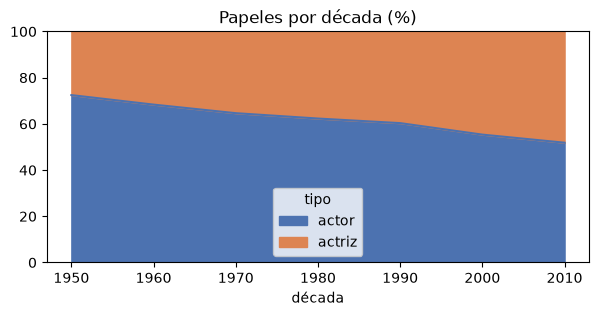

Años con más protagonistas actrices que actores:
tipo  actor  actriz
año                
1970     15      19
1974      9      12
1978     15      18
1992     12      17
1994     16      18
1997      9      12
2000     17      20
2006     15      18
2017     13      16


In [15]:
rng = np.random.default_rng(1950)
partes = []
for año in range(1950, 2020):
    proporcion = 0.25 + 0.25 * (año - 1950) / 69
    for p in range(rng.integers(20, 41)):
        posicion = np.arange(1, rng.integers(5, 13) + 1)
        partes.append(pd.DataFrame({
            "año": año,
            "pelicula": f"Película {año}-{p:02d}",
            "tipo": np.where(rng.random(len(posicion)) < proporcion, "actriz", "actor"),
            "posicion": posicion,
        }))
repartos = pd.concat(partes, ignore_index=True)
print(repartos.shape, "\n", repartos.head(3), sep="")

anual = pd.crosstab(repartos["año"], repartos["tipo"], normalize="index").mul(100)
print("\nPorcentaje anual:\n", anual.iloc[[0, 1, -2, -1]].round(1), sep="")
assert np.allclose(anual.sum(axis=1), 100)

decada = (repartos["año"] // 10 * 10).rename("década")
por_decada = pd.crosstab(decada, repartos["tipo"], normalize="index").mul(100)
print("\nPor décadas:\n", por_decada.round(1), sep="")
ax = por_decada.plot.area(figsize=(7, 3), color=["#4c72b0", "#dd8452"], ylim=(0, 100),
                          title="Papeles por década (%)", xlabel="década")
plt.show()

protagonistas = repartos[repartos["posicion"] == 1]
conteo = pd.crosstab(protagonistas["año"], protagonistas["tipo"])
mas_actrices = conteo[conteo["actriz"] > conteo["actor"]]
print("Años con más protagonistas actrices que actores:\n", mas_actrices, sep="")
assert len(mas_actrices) == sum(
    (g["tipo"] == "actriz").sum() > (g["tipo"] == "actor").sum() for _, g in protagonistas.groupby("año"))
assert conteo.to_numpy().sum() == repartos["pelicula"].nunique()